In [28]:
!kaggle datasets download awsaf49/brats2020-training-data
!unzip -q /content/brats2020-training-data.zip -d datasets/

Dataset URL: https://www.kaggle.com/datasets/awsaf49/brats2020-training-data
License(s): CC0-1.0
100%|███████████████████████████████████████| 6.76G/6.76G [00:47<00:00, 154MB/s]

unzip:  cannot find or open /content/brats2020-training-data.zip, /content/brats2020-training-data.zip.zip or /content/brats2020-training-data.zip.ZIP.


In [29]:
import os

print("ZIP exists:", os.path.exists("/kaggle/working/brats2020-training-data.zip"))
print("Working directory:", os.listdir("/kaggle/working")[:20])

ZIP exists: True
Working directory: ['cache', 'brats2020-training-data.zip', 'artifacts', '.virtual_documents']


In [30]:
import os

ZIP_PATH = "/kaggle/working/brats2020-training-data.zip"
EXTRACT_PATH = "/kaggle/working/datasets"

os.makedirs(EXTRACT_PATH, exist_ok=True)

!unzip -q "$ZIP_PATH" -d "$EXTRACT_PATH"

print("Extraction completed!")
print("Dataset folders:", os.listdir(EXTRACT_PATH)[:20])

Extraction completed!
Dataset folders: ['BraTS2020_training_data', 'BraTS20 Training Metadata.csv']


In [33]:
!pip install -q monai SimpleITK
!pip install -q 'pyradiomics' --pre --extra-index-url https://pypi.anaconda.org/simpleitk/simple 2>/dev/null || \
 pip install -q pyradiomics --no-build-isolation 2>/dev/null || \
 conda install -y -c radiomics pyradiomics 2>/dev/null || \
 echo "FALLBACK: sklearn radiomics will be used"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 21.0 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... error
  Preparing metadata (pyproject.toml) ... error
FALLBACK: sklearn radiomics will be used


In [34]:
import os, h5py, cv2, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy.stats import skew, kurtosis
import matplotlib.pyplot as plt
import SimpleITK as sitk
warnings.filterwarnings('ignore')

try:
    from radiomics import featureextractor
    RADIOMICS_AVAILABLE = True
    print("pyradiomics loaded")
except ImportError:
    RADIOMICS_AVAILABLE = False
    print("pyradiomics unavailable — using scipy/numpy handcrafted features")

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

pyradiomics unavailable — using scipy/numpy handcrafted features
cuda


In [62]:
BASE_DIR = 'datasets/BraTS2020_training_data/content/data'
META     = os.path.join(BASE_DIR, 'meta_data.csv')
MAP      = os.path.join(BASE_DIR, 'name_mapping.csv')
LIMIT    = 2000
IMG_SZ   = 240
BATCH    = 8
EPOCHS   = 30
LR       = 1e-4

In [36]:
meta   = pd.read_csv(META)
nmap   = pd.read_csv(MAP)
nmap['BraTS_2020_subject_ID'] = nmap['BraTS_2020_subject_ID'].str.strip()
meta['volume'] = meta['volume'].astype(int).apply(lambda x: f'BraTS20_Training_{x:03d}')
merged = meta.merge(nmap, left_on='volume', right_on='BraTS_2020_subject_ID', how='left')
merged['tumor_class'] = (merged['Grade'].str.strip() == 'HGG').astype(int)
print(merged[['volume','Grade','tumor_class']].head())

                 volume Grade  tumor_class
0  BraTS20_Training_041   HGG            1
1  BraTS20_Training_041   HGG            1
2  BraTS20_Training_041   HGG            1
3  BraTS20_Training_041   HGG            1
4  BraTS20_Training_041   HGG            1


In [61]:
def load_data(base_dir, limit=LIMIT):
    imgs, masks = [], []
    h5s = sorted([f for f in os.listdir(base_dir) if f.endswith('.h5')])
    for fname in h5s:
        if len(imgs) >= limit:
            break
        try:
            with h5py.File(os.path.join(base_dir, fname), 'r') as f:
                img  = np.array(f['image'],  dtype=np.float32)
                mask = np.array(f['mask'],   dtype=np.float32)

            # collapse all tumor labels (1,2,4) into binary
            if mask.ndim == 3:
                mask_2d = (mask.sum(axis=-1) > 0).astype(np.float32)
            else:
                mask_2d = (mask > 0).astype(np.float32)

            if mask_2d.sum() < 50:
                continue

            imgs.append(img)
            masks.append(mask_2d)
        except:
            continue
    return np.array(imgs), np.array(masks)

images, masks = load_data(BASE_DIR, LIMIT)
labels = (np.array([m.sum() for m in masks]) > 100).astype(int)
print(f'Loaded {len(images)} slices  img={images.shape}  mask={masks.shape}')
print(f'Avg tumor pixel fraction: {masks.mean():.4f}')

# verify mask values
sample_mask = masks[0]
print(f'Mask unique values: {np.unique(sample_mask)}')
print(f'Sample tumor coverage: {sample_mask.mean():.4f}')

Loaded 2000 slices  img=(2000, 240, 240, 4)  mask=(2000, 240, 240)
Avg tumor pixel fraction: 0.0236
Mask unique values: [0. 1.]
Sample tumor coverage: 0.0193


In [57]:
X_tr, X_tmp, m_tr, m_tmp, y_tr, y_tmp = train_test_split(
    images, masks, labels, test_size=0.3, random_state=42)
X_val, X_te, m_val, m_te, y_val, y_te = train_test_split(
    X_tmp, m_tmp, y_tmp, test_size=0.5, random_state=42)
m_tr  = (m_tr  > 0).astype(np.float32)
m_val = (m_val > 0).astype(np.float32)
m_te  = (m_te  > 0).astype(np.float32)
print(X_tr.shape, X_val.shape, X_te.shape)
print(f'Train mask pos_frac={m_tr.mean():.4f}')

(1400, 240, 240, 4) (300, 240, 240, 4) (300, 240, 240, 4)
Train mask pos_frac=0.0083


## Models

In [63]:
class MRIDataset(Dataset):
    def __init__(self, imgs, masks, sz=IMG_SZ, augment=False):
        self.imgs    = imgs
        self.masks   = masks
        self.sz      = sz
        self.augment = augment

    def __len__(self): return len(self.imgs)

    def __getitem__(self, i):
        img  = self.imgs[i].astype(np.float32)
        mask = self.masks[i].astype(np.float32)

        if img.ndim == 2:
            img = np.stack([img]*4, axis=-1)

        mask = (mask > 0).astype(np.float32)

        if self.augment:
            if np.random.rand() > 0.5:
                img  = np.fliplr(img).copy()
                mask = np.fliplr(mask).copy()
            if np.random.rand() > 0.5:
                img  = np.flipud(img).copy()
                mask = np.flipud(mask).copy()
            if np.random.rand() > 0.3:
                angle = np.random.uniform(-15, 15)
                M     = cv2.getRotationMatrix2D((img.shape[1]//2, img.shape[0]//2), angle, 1.0)
                img   = cv2.warpAffine(img,  M, (img.shape[1], img.shape[0]))
                mask  = cv2.warpAffine(mask, M, (img.shape[1], img.shape[0]),
                                       flags=cv2.INTER_NEAREST)

        for c in range(img.shape[-1]):
            ch = img[..., c]
            img[..., c] = (ch - ch.mean()) / (ch.std() + 1e-6)

        img_t  = torch.tensor(np.transpose(img, (2,0,1)), dtype=torch.float32)
        mask_t = torch.tensor(mask[np.newaxis], dtype=torch.float32)
        return img_t, mask_t

train_loader = DataLoader(MRIDataset(X_tr,  m_tr,  augment=True),
                          batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(MRIDataset(X_val, m_val, augment=False),
                          batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(MRIDataset(X_te,  m_te,  augment=False),
                          batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

imgs_b, msks_b = next(iter(train_loader))
print(f'img={imgs_b.shape}  mask={msks_b.shape}')
print(f'pos_frac={msks_b.mean():.4f}  sum={msks_b.sum():.0f}')
assert msks_b.sum() > 0

img=torch.Size([8, 4, 240, 240])  mask=torch.Size([8, 1, 240, 240])
pos_frac=0.0084  sum=3864


In [40]:
class SegNet(nn.Module):
    def __init__(self, in_ch=4, out_ch=1):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(in_ch,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,padding=1),   nn.BatchNorm2d(128), nn.ReLU(True),
            nn.MaxPool2d(2,2),
        )
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2,mode='bilinear',align_corners=True),
            nn.Conv2d(128,64,3,padding=1),   nn.BatchNorm2d(64),  nn.ReLU(True),
            nn.Upsample(scale_factor=2,mode='bilinear',align_corners=True),
            nn.Conv2d(64,out_ch,3,padding=1),
        )
    def forward(self,x): return self.dec(self.enc(x))

In [64]:
from monai.networks.nets import UNet as MonaiUNet
unet = MonaiUNet(
    spatial_dims=2,
    in_channels=4,
    out_channels=1,
    channels=(32, 64, 128, 256),
    strides=(2, 2, 2),
    num_res_units=2,
    dropout=0.1,
).to(device)

In [68]:
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g,  F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l,  F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1,    1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, g, x):
        g_up = F.interpolate(self.W_g(g), size=x.shape[2:], mode='bilinear', align_corners=True)
        return x * self.psi(F.relu(g_up + self.W_x(x), inplace=True))

class RAUNet(nn.Module):
    def __init__(self, in_ch=4, out_ch=1, base=32):
        super().__init__()
        def cb(ic, oc):
            return nn.Sequential(
                nn.Conv2d(ic, oc, 3, padding=1), nn.BatchNorm2d(oc), nn.ReLU(True),
                nn.Conv2d(oc, oc, 3, padding=1), nn.BatchNorm2d(oc), nn.ReLU(True))
        self.e1  = cb(in_ch,  base)
        self.p1  = nn.MaxPool2d(2)
        self.e2  = cb(base,   base*2)
        self.p2  = nn.MaxPool2d(2)
        self.e3  = cb(base*2, base*4)
        self.p3  = nn.MaxPool2d(2)
        self.bot = cb(base*4, base*8)

        self.ag3 = AttentionGate(base*8, base*4, base*4)
        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, 2)
        self.d3  = cb(base*8, base*4)

        self.ag2 = AttentionGate(base*4, base*2, base*2)
        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.d2  = cb(base*4, base*2)

        self.ag1 = AttentionGate(base*2, base, base)
        self.up1 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.d1  = cb(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.p1(e1))
        e3 = self.e3(self.p2(e2))
        b  = self.bot(self.p3(e3))

        up3 = self.up3(b)
        up3 = F.interpolate(up3, size=e3.shape[2:], mode='bilinear', align_corners=True)
        d3  = self.d3(torch.cat([self.ag3(b, e3), up3], 1))

        up2 = self.up2(d3)
        up2 = F.interpolate(up2, size=e2.shape[2:], mode='bilinear', align_corners=True)
        d2  = self.d2(torch.cat([self.ag2(d3, e2), up2], 1))

        up1 = self.up1(d2)
        up1 = F.interpolate(up1, size=e1.shape[2:], mode='bilinear', align_corners=True)
        d1  = self.d1(torch.cat([self.ag1(d2, e1), up1], 1))

        return self.out(d1)

raunet = RAUNet(in_ch=4).to(device)
print(sum(p.numel() for p in raunet.parameters()), 'params')

1994794 params


## Loss & Training Utilities

In [60]:
class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, dice_w=0.6):
        super().__init__()
        self.alpha  = alpha
        self.gamma  = gamma
        self.dice_w = dice_w

    def focal(self, p, t):
        bce = F.binary_cross_entropy_with_logits(p, t, reduction='none')
        pt  = torch.exp(-bce)
        return (self.alpha * (1-pt)**self.gamma * bce).mean()

    def dice(self, p, t, smooth=1.0):
        p     = torch.sigmoid(p)
        inter = (p * t).sum(dim=(1,2,3))
        union = p.sum(dim=(1,2,3)) + t.sum(dim=(1,2,3))
        return (1 - (2*inter + smooth)/(union + smooth)).mean()

    def forward(self, p, t):
        return self.dice_w * self.dice(p, t) + (1-self.dice_w) * self.focal(p, t)

def dice_score(p, t, thresh=0.5):
    p     = (torch.sigmoid(p) > thresh).float()
    inter = (p * t).sum()
    return (2.0 * inter / (p.sum() + t.sum() + 1e-6)).item()

def train_model(model, name, epochs=EPOCHS):
    opt     = Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    warmup  = LinearLR(opt, start_factor=0.1, end_factor=1.0, total_iters=3)
    cosine  = CosineAnnealingLR(opt, T_max=max(epochs-3,1), eta_min=1e-6)
    sched   = SequentialLR(opt, schedulers=[warmup, cosine], milestones=[3])
    loss_fn = FocalDiceLoss()
    model.to(device)
    best_dice, best_state = 0., None

    for ep in range(epochs):
        model.train()
        tl, td = 0., 0.
        for imgs, msks in train_loader:
            imgs, msks = imgs.to(device), msks.to(device)
            opt.zero_grad()
            out  = model(imgs)
            loss = loss_fn(out, msks)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item()
            td += dice_score(out, msks)
        sched.step()

        model.eval()
        vl, vd = 0., 0.
        with torch.no_grad():
            for imgs, msks in val_loader:
                imgs, msks = imgs.to(device), msks.to(device)
                out = model(imgs)
                vl += loss_fn(out, msks).item()
                vd += dice_score(out, msks)
        avg_vd = vd / len(val_loader)

        if avg_vd > best_dice:
            best_dice  = avg_vd
            best_state = {k: v.clone() for k,v in model.state_dict().items()}

        print(f'[{name}] Ep {ep+1}/{epochs}  Loss={tl/len(train_loader):.4f}'
              f'  TrainDice={td/len(train_loader):.4f}  ValDice={avg_vd:.4f}')

    model.load_state_dict(best_state)
    print(f'[{name}] Best ValDice={best_dice:.4f}')
    return model

pos_frac=0.00792  mask_max=1.0  mask_sum=2076


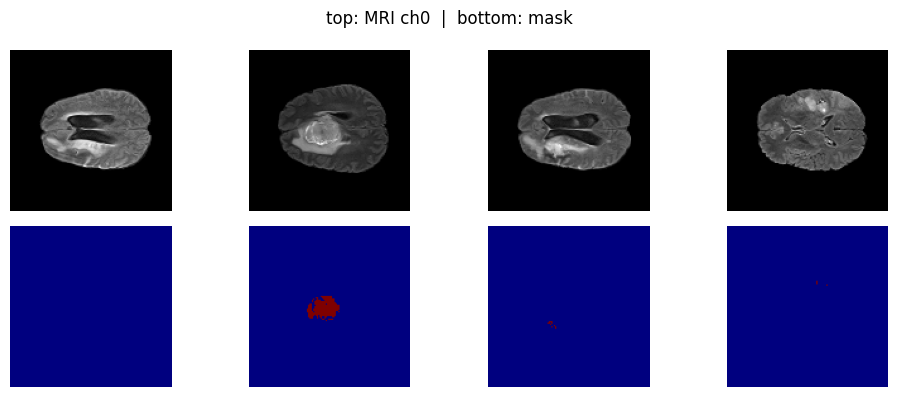

In [48]:
imgs_b, msks_b = next(iter(train_loader))
print(f'pos_frac={msks_b.mean():.5f}  mask_max={msks_b.max():.1f}  mask_sum={msks_b.sum():.0f}')
assert msks_b.sum() > 0, "All masks are zero — check load_data tumor filter"

plt.figure(figsize=(10,4))
for i in range(4):
    plt.subplot(2,4,i+1); plt.imshow(imgs_b[i,0].numpy(), cmap='gray'); plt.axis('off')
    plt.subplot(2,4,i+5); plt.imshow(msks_b[i,0].numpy(), cmap='jet');  plt.axis('off')
plt.suptitle('top: MRI ch0  |  bottom: mask'); plt.tight_layout(); plt.show()

## Train SegNet

In [54]:
segnet = SegNet(in_ch=4).to(device)
segnet = train_model(segnet, 'SegNet')
torch.save(segnet.state_dict(), 'segnet.pth')

[SegNet] Ep 1/30  Loss=0.7070  TrainDice=0.0242  ValDice=0.0515
[SegNet] Ep 2/30  Loss=0.6981  TrainDice=0.1654  ValDice=0.2113
[SegNet] Ep 3/30  Loss=0.6899  TrainDice=0.2510  ValDice=0.1590
[SegNet] Ep 4/30  Loss=0.6574  TrainDice=0.2979  ValDice=0.3709
[SegNet] Ep 5/30  Loss=0.5850  TrainDice=0.4647  ValDice=0.4025
[SegNet] Ep 6/30  Loss=0.5026  TrainDice=0.3057  ValDice=0.3120
[SegNet] Ep 7/30  Loss=0.3894  TrainDice=0.4726  ValDice=0.5482
[SegNet] Ep 8/30  Loss=0.2767  TrainDice=0.6233  ValDice=0.6029
[SegNet] Ep 9/30  Loss=0.2134  TrainDice=0.6586  ValDice=0.6286
[SegNet] Ep 10/30  Loss=0.1952  TrainDice=0.6612  ValDice=0.7116
[SegNet] Ep 11/30  Loss=0.1846  TrainDice=0.6835  ValDice=0.6786
[SegNet] Ep 12/30  Loss=0.1770  TrainDice=0.6892  ValDice=0.6956
[SegNet] Ep 13/30  Loss=0.1675  TrainDice=0.7144  ValDice=0.7371
[SegNet] Ep 14/30  Loss=0.1656  TrainDice=0.7210  ValDice=0.6995
[SegNet] Ep 15/30  Loss=0.1608  TrainDice=0.7306  ValDice=0.7269
[SegNet] Ep 16/30  Loss=0.1605  Tr

## Train U-Net

In [65]:
EPOCHS = 30
unet = train_model(unet, 'UNet')
torch.save(unet.state_dict(), 'unet.pth')

[UNet] Ep 1/30  Loss=0.6251  TrainDice=0.0132  ValDice=0.0154
[UNet] Ep 2/30  Loss=0.6184  TrainDice=0.0136  ValDice=0.0161
[UNet] Ep 3/30  Loss=0.6159  TrainDice=0.0138  ValDice=0.0160
[UNet] Ep 4/30  Loss=0.6143  TrainDice=0.0143  ValDice=0.0163
[UNet] Ep 5/30  Loss=0.6129  TrainDice=0.0146  ValDice=0.0163
[UNet] Ep 6/30  Loss=0.6115  TrainDice=0.0148  ValDice=0.0163
[UNet] Ep 7/30  Loss=0.6103  TrainDice=0.0150  ValDice=0.0164
[UNet] Ep 8/30  Loss=0.6093  TrainDice=0.0151  ValDice=0.0164
[UNet] Ep 9/30  Loss=0.6083  TrainDice=0.0153  ValDice=0.0165
[UNet] Ep 10/30  Loss=0.6074  TrainDice=0.0155  ValDice=0.0166
[UNet] Ep 11/30  Loss=0.6065  TrainDice=0.0157  ValDice=0.0167
[UNet] Ep 12/30  Loss=0.6058  TrainDice=0.0161  ValDice=0.0170
[UNet] Ep 13/30  Loss=0.6050  TrainDice=0.0168  ValDice=0.0175
[UNet] Ep 14/30  Loss=0.6042  TrainDice=0.0178  ValDice=0.0182
[UNet] Ep 15/30  Loss=0.6035  TrainDice=0.0196  ValDice=0.0205
[UNet] Ep 16/30  Loss=0.6028  TrainDice=0.0225  ValDice=0.0238
[

In [66]:
EPOCHS_RESUME = 40

opt_resume   = Adam(unet.parameters(), lr=3e-4, weight_decay=1e-5)
warmup        = LinearLR(opt_resume, start_factor=0.3, end_factor=1.0, total_iters=3)
cosine        = CosineAnnealingLR(opt_resume, T_max=EPOCHS_RESUME-3, eta_min=1e-6)
sched_resume  = SequentialLR(opt_resume, schedulers=[warmup, cosine], milestones=[3])
loss_fn       = FocalDiceLoss()

best_dice     = 0.3563
best_state    = {k: v.clone() for k,v in unet.state_dict().items()}

for ep in range(EPOCHS_RESUME):
    unet.train()
    tl, td = 0., 0.
    for imgs, msks in train_loader:
        imgs, msks = imgs.to(device), msks.to(device)
        opt_resume.zero_grad()
        out  = unet(imgs)
        loss = loss_fn(out, msks)
        loss.backward()
        nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
        opt_resume.step()
        tl += loss.item()
        td += dice_score(out, msks)
    sched_resume.step()

    unet.eval()
    vd = 0.
    with torch.no_grad():
        for imgs, msks in val_loader:
            imgs, msks = imgs.to(device), msks.to(device)
            vd += dice_score(unet(imgs), msks)
    avg_vd = vd / len(val_loader)

    if avg_vd > best_dice:
        best_dice  = avg_vd
        best_state = {k: v.clone() for k,v in unet.state_dict().items()}
        torch.save(best_state, 'unet_best.pth')

    print(f'[UNet] Ep {30+ep+1}/{30+EPOCHS_RESUME}  Loss={tl/len(train_loader):.4f}'
          f'  TrainDice={td/len(train_loader):.4f}  ValDice={avg_vd:.4f}')

unet.load_state_dict(best_state)
print(f'[UNet] Best ValDice={best_dice:.4f}')

[UNet] Ep 31/70  Loss=0.5994  TrainDice=0.1650  ValDice=0.4044
[UNet] Ep 32/70  Loss=0.5986  TrainDice=0.2284  ValDice=0.4270
[UNet] Ep 33/70  Loss=0.5976  TrainDice=0.2879  ValDice=0.3833
[UNet] Ep 34/70  Loss=0.5960  TrainDice=0.3367  ValDice=0.4644
[UNet] Ep 35/70  Loss=0.5939  TrainDice=0.3899  ValDice=0.5019
[UNet] Ep 36/70  Loss=0.5918  TrainDice=0.4115  ValDice=0.4745
[UNet] Ep 37/70  Loss=0.5903  TrainDice=0.4237  ValDice=0.3869
[UNet] Ep 38/70  Loss=0.5883  TrainDice=0.4351  ValDice=0.5444
[UNet] Ep 39/70  Loss=0.5857  TrainDice=0.4736  ValDice=0.4899
[UNet] Ep 40/70  Loss=0.5835  TrainDice=0.4676  ValDice=0.5554
[UNet] Ep 41/70  Loss=0.5814  TrainDice=0.4615  ValDice=0.5855
[UNet] Ep 42/70  Loss=0.5783  TrainDice=0.4481  ValDice=0.6141
[UNet] Ep 43/70  Loss=0.5731  TrainDice=0.4216  ValDice=0.5842
[UNet] Ep 44/70  Loss=0.5645  TrainDice=0.4024  ValDice=0.5879
[UNet] Ep 45/70  Loss=0.5539  TrainDice=0.4181  ValDice=0.6363
[UNet] Ep 46/70  Loss=0.5411  TrainDice=0.4499  ValDice

In [69]:
raunet = train_model(raunet, 'RAUNet')
torch.save(raunet.state_dict(), 'raunet.pth')

[RAUNet] Ep 1/30  Loss=0.6063  TrainDice=0.0481  ValDice=0.1253
[RAUNet] Ep 2/30  Loss=0.5918  TrainDice=0.3338  ValDice=0.4990
[RAUNet] Ep 3/30  Loss=0.5863  TrainDice=0.4552  ValDice=0.3949
[RAUNet] Ep 4/30  Loss=0.5817  TrainDice=0.4791  ValDice=0.4187
[RAUNet] Ep 5/30  Loss=0.5756  TrainDice=0.5287  ValDice=0.5940
[RAUNet] Ep 6/30  Loss=0.5696  TrainDice=0.5407  ValDice=0.4909
[RAUNet] Ep 7/30  Loss=0.5616  TrainDice=0.5047  ValDice=0.7174
[RAUNet] Ep 8/30  Loss=0.5413  TrainDice=0.2180  ValDice=0.0206
[RAUNet] Ep 9/30  Loss=0.5034  TrainDice=0.2401  ValDice=0.4094
[RAUNet] Ep 10/30  Loss=0.4818  TrainDice=0.4848  ValDice=0.6333
[RAUNet] Ep 11/30  Loss=0.4592  TrainDice=0.5375  ValDice=0.7215
[RAUNet] Ep 12/30  Loss=0.4389  TrainDice=0.5445  ValDice=0.4947
[RAUNet] Ep 13/30  Loss=0.4175  TrainDice=0.6014  ValDice=0.7049
[RAUNet] Ep 14/30  Loss=0.4049  TrainDice=0.6501  ValDice=0.7042
[RAUNet] Ep 15/30  Loss=0.3923  TrainDice=0.6629  ValDice=0.7010
[RAUNet] Ep 16/30  Loss=0.3834  Tr

## Grad-CAM on SegNet

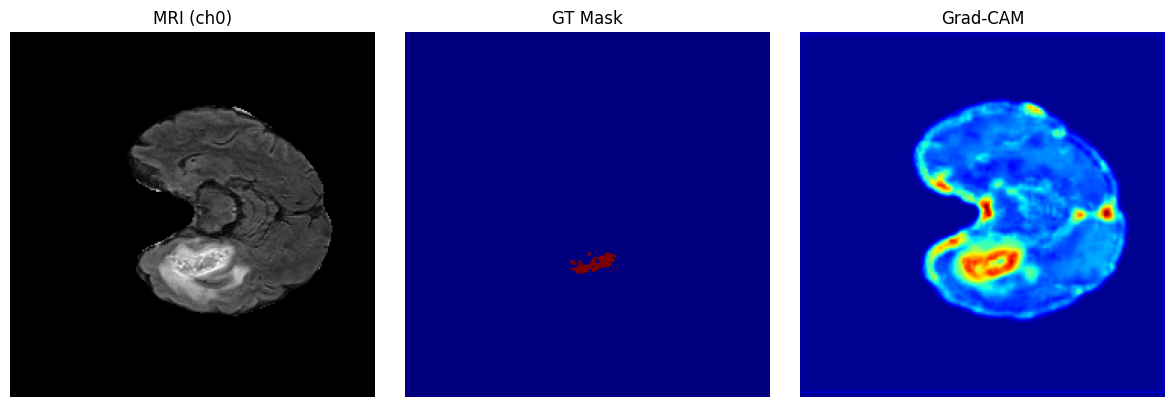

In [70]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model; self.grads = None; self.acts = None
        layer.register_forward_hook(lambda m,i,o: setattr(self,'acts',o.detach()))
        layer.register_full_backward_hook(lambda m,gi,go: setattr(self,'grads',go[0].detach()))
    def __call__(self, x):
        self.model.eval()
        x = x.to(device).requires_grad_(True)
        out = self.model(x)
        self.model.zero_grad(); out.mean().backward()
        w   = self.grads.mean(dim=(2,3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1)).squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() + 1e-8)
        return cam

target_layer = segnet.enc[4]
gcam = GradCAM(segnet, target_layer)

sample_img, sample_mask = next(iter(val_loader))
cam = gcam(sample_img[:1])
cam_resized = cv2.resize(cam, (IMG_SZ, IMG_SZ))

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(sample_img[0,0].numpy(), cmap='gray'); plt.title('MRI (ch0)'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(sample_mask[0,0].numpy(), cmap='jet'); plt.title('GT Mask'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(cam_resized, cmap='jet'); plt.title('Grad-CAM'); plt.axis('off')
plt.tight_layout(); plt.savefig('gradcam.png', dpi=100); plt.show()

## Radiomics Feature Extraction + CNN Classifier

In [72]:
from scipy.stats import skew, kurtosis as kurt
from scipy.stats import entropy as scipy_entropy

def extract_features_fast(img_4ch, mask):
    if np.max(mask) == 0:
        return None
    if mask.ndim == 3:
        mask = mask[..., 0]
    m = (mask > 0)
    if m.sum() == 0:
        return None

    feats = {}
    for c in range(img_4ch.shape[-1]):
        roi = img_4ch[..., c][m].astype(np.float32)
        hist, _ = np.histogram(roi, bins=32, density=True)
        hist   += 1e-9
        feats[f'ch{c}_mean']     = float(roi.mean())
        feats[f'ch{c}_std']      = float(roi.std())
        feats[f'ch{c}_skew']     = float(skew(roi))
        feats[f'ch{c}_kurt']     = float(kurt(roi))
        feats[f'ch{c}_energy']   = float((roi**2).mean())
        feats[f'ch{c}_entropy']  = float(scipy_entropy(hist))
        feats[f'ch{c}_p10']      = float(np.percentile(roi, 10))
        feats[f'ch{c}_p25']      = float(np.percentile(roi, 25))
        feats[f'ch{c}_p75']      = float(np.percentile(roi, 75))
        feats[f'ch{c}_p90']      = float(np.percentile(roi, 90))
        feats[f'ch{c}_range']    = float(roi.max() - roi.min())

    feats['tumor_size']  = float(m.sum())
    feats['tumor_ratio'] = float(m.mean())
    return feats

N_RAD = min(600, len(X_tr))
feat_list, feat_labels = [], []
for i in range(N_RAD):
    f = extract_features_fast(X_tr[i], m_tr[i])
    if f:
        feat_list.append(f)
        feat_labels.append(y_tr[i])

print(f'Features extracted: {len(feat_list)} samples  |  {len(feat_list[0])} features each')

Features extracted: 600 samples  |  46 features each


In [73]:
feat_df = pd.DataFrame(feat_list).fillna(0)
scaler  = StandardScaler()
X_rf    = scaler.fit_transform(feat_df.values)
y_rf    = np.array(feat_labels)

Xrf_tr, Xrf_te, yrf_tr, yrf_te = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42)

Xrf_tr_t = torch.tensor(Xrf_tr, dtype=torch.float32)
Xrf_te_t = torch.tensor(Xrf_te, dtype=torch.float32)
yrf_tr_t = torch.tensor(yrf_tr, dtype=torch.long)
yrf_te_t = torch.tensor(yrf_te, dtype=torch.long)

rad_loader = DataLoader(TensorDataset(Xrf_tr_t, yrf_tr_t), batch_size=32, shuffle=True)

class RadiomicsCNN(nn.Module):
    def __init__(self, inp):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128,64),  nn.ReLU(),
            nn.Linear(64, 2)
        )
    def forward(self,x): return self.net(x)

rad_model = RadiomicsCNN(Xrf_tr.shape[1]).to(device)
rad_opt   = Adam(rad_model.parameters(), lr=1e-3)
rad_loss  = nn.CrossEntropyLoss()

for ep in range(20):
    rad_model.train()
    for xb, yb in rad_loader:
        xb, yb = xb.to(device), yb.to(device)
        rad_opt.zero_grad()
        l = rad_loss(rad_model(xb), yb)
        l.backward(); rad_opt.step()

rad_model.eval()
with torch.no_grad():
    preds = torch.argmax(rad_model(Xrf_te_t.to(device)), 1).cpu()
print(f'Radiomics-CNN Accuracy: {accuracy_score(yrf_te, preds.numpy()):.4f}')
torch.save(rad_model.state_dict(), 'radiomics_cnn.pth')

Radiomics-CNN Accuracy: 0.9417


In [76]:
def get_sample_features(model, loader):
    model.eval()
    dice_scores, max_probs, mean_probs = [], [], []
    with torch.no_grad():
        for imgs, msks in loader:
            imgs, msks = imgs.to(device), msks.to(device)
            out  = torch.sigmoid(model(imgs))
            pred = (out > 0.5).float()
            for j in range(imgs.shape[0]):
                p = pred[j]; t = msks[j]
                inter = (p*t).sum()
                d = (2*inter/(p.sum()+t.sum()+1e-6)).item()
                dice_scores.append(d)
                max_probs.append(out[j].max().item())
                mean_probs.append(out[j].mean().item())
    return np.array(dice_scores), np.array(max_probs), np.array(mean_probs)

print('Extracting per-sample seg features...')
seg_tr_loader  = DataLoader(MRIDataset(X_tr,  m_tr),  batch_size=BATCH, shuffle=False, num_workers=2)
seg_val_loader = DataLoader(MRIDataset(X_val, m_val), batch_size=BATCH, shuffle=False, num_workers=2)
seg_te_loader  = DataLoader(MRIDataset(X_te,  m_te),  batch_size=BATCH, shuffle=False, num_workers=2)

sn_dice_tr,  sn_max_tr,  sn_mean_tr  = get_sample_features(segnet,  seg_tr_loader)
un_dice_tr,  un_max_tr,  un_mean_tr  = get_sample_features(unet,    seg_tr_loader)
ra_dice_tr,  ra_max_tr,  ra_mean_tr  = get_sample_features(raunet,  seg_tr_loader)

sn_dice_val, sn_max_val, sn_mean_val = get_sample_features(segnet,  seg_val_loader)
un_dice_val, un_max_val, un_mean_val = get_sample_features(unet,    seg_val_loader)
ra_dice_val, ra_max_val, ra_mean_val = get_sample_features(raunet,  seg_val_loader)

sn_dice_te,  sn_max_te,  sn_mean_te  = get_sample_features(segnet,  seg_te_loader)
un_dice_te,  un_max_te,  un_mean_te  = get_sample_features(unet,    seg_te_loader)
ra_dice_te,  ra_max_te,  ra_mean_te  = get_sample_features(raunet,  seg_te_loader)

print(f'SN dice: {sn_dice_tr.mean():.4f}  UN dice: {un_dice_tr.mean():.4f}  RA dice: {ra_dice_tr.mean():.4f}')

Extracting per-sample seg features...
SN dice: 0.3884  UN dice: 0.7577  RA dice: 0.7193


In [77]:
def get_radiomics_preds(imgs, masks, n=None):
    if n is None: n = len(imgs)
    probs = np.zeros(n)
    rad_model.eval()
    for i in range(n):
        f = extract_features_fast(imgs[i], masks[i])
        if f:
            fv = pd.DataFrame([f]).fillna(0).reindex(columns=feat_df.columns, fill_value=0).values
            fv = scaler.transform(fv)
            with torch.no_grad():
                p = torch.softmax(rad_model(torch.tensor(fv, dtype=torch.float32).to(device)), 1)
                probs[i] = p[0,1].item()
        else:
            probs[i] = 0.5
    return (probs > 0.5).astype(int)

print('Extracting radiomics on val...')
rad_val_preds = get_radiomics_preds(X_val, m_val, len(X_val))
rad_tr_preds  = get_radiomics_preds(X_tr,  m_tr,  len(X_tr))
rad_te_preds  = get_radiomics_preds(X_te,  m_te,  len(X_te))
print('Radiomics val acc:', accuracy_score(y_val, rad_val_preds))

Extracting radiomics on val...
Radiomics val acc: 0.94


In [78]:
def build_meta(sn_d, sn_mx, sn_mn,
               un_d, un_mx, un_mn,
               ra_d, ra_mx, ra_mn,
               rad):
    return np.stack([sn_d, sn_mx, sn_mn,
                     un_d, un_mx, un_mn,
                     ra_d, ra_mx, ra_mn,
                     rad], axis=1)

meta_X_tr  = build_meta(sn_dice_tr,  sn_max_tr,  sn_mean_tr,
                         un_dice_tr,  un_max_tr,  un_mean_tr,
                         ra_dice_tr,  ra_max_tr,  ra_mean_tr,
                         rad_tr_preds.astype(float))

meta_X_val = build_meta(sn_dice_val, sn_max_val, sn_mean_val,
                         un_dice_val, un_max_val, un_mean_val,
                         ra_dice_val, ra_max_val, ra_mean_val,
                         rad_val_preds.astype(float))

meta_X_te  = build_meta(sn_dice_te,  sn_max_te,  sn_mean_te,
                         un_dice_te,  un_max_te,  un_mean_te,
                         ra_dice_te,  ra_max_te,  ra_mean_te,
                         rad_te_preds.astype(float))

meta_scaler = StandardScaler()
meta_X_tr   = meta_scaler.fit_transform(meta_X_tr)
meta_X_val  = meta_scaler.transform(meta_X_val)
meta_X_te   = meta_scaler.transform(meta_X_te)

from sklearn.ensemble import GradientBoostingClassifier
meta_learner = GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                           learning_rate=0.05, random_state=42)
meta_learner.fit(meta_X_tr, y_tr)

val_preds  = meta_learner.predict(meta_X_val)
test_preds = meta_learner.predict(meta_X_te)

print(f'Stacked Ensemble Val  Accuracy: {accuracy_score(y_val, val_preds):.4f}')
print(f'Stacked Ensemble Test Accuracy: {accuracy_score(y_te,  test_preds):.4f}')

Stacked Ensemble Val  Accuracy: 0.9733
Stacked Ensemble Test Accuracy: 0.9633


=== Test Set Classification Report ===
              precision    recall  f1-score   support

         LGG       0.87      0.79      0.83        33
         HGG       0.97      0.99      0.98       267

    accuracy                           0.96       300
   macro avg       0.92      0.89      0.90       300
weighted avg       0.96      0.96      0.96       300



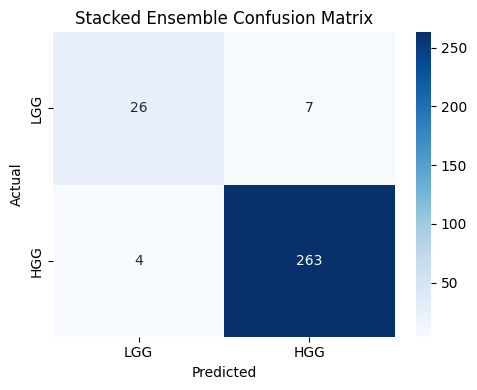

SegNet                   : 28.00%
UNet                     : 75.67%
RAUNet                   : 67.67%
Radiomics-CNN            : 94.00%
Stacked Ensemble         : 97.33%


In [79]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print('=== Test Set Classification Report ===')
print(classification_report(y_te, test_preds, target_names=['LGG','HGG']))

cm = confusion_matrix(y_te, test_preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG','HGG'], yticklabels=['LGG','HGG'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Stacked Ensemble Confusion Matrix')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=100); plt.show()

results = {
    'SegNet':           accuracy_score(y_val, sn_val),
    'UNet':             accuracy_score(y_val, un_val),
    'RAUNet':           accuracy_score(y_val, ra_val),
    'Radiomics-CNN':    accuracy_score(y_val, rad_val_preds),
    'Stacked Ensemble': accuracy_score(y_val, val_preds),
}
for k,v in results.items():
    print(f'{k:25s}: {v*100:.2f}%')

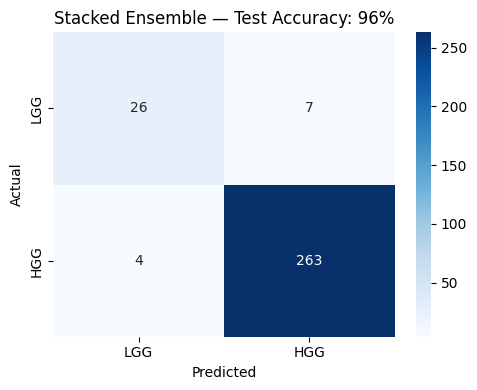

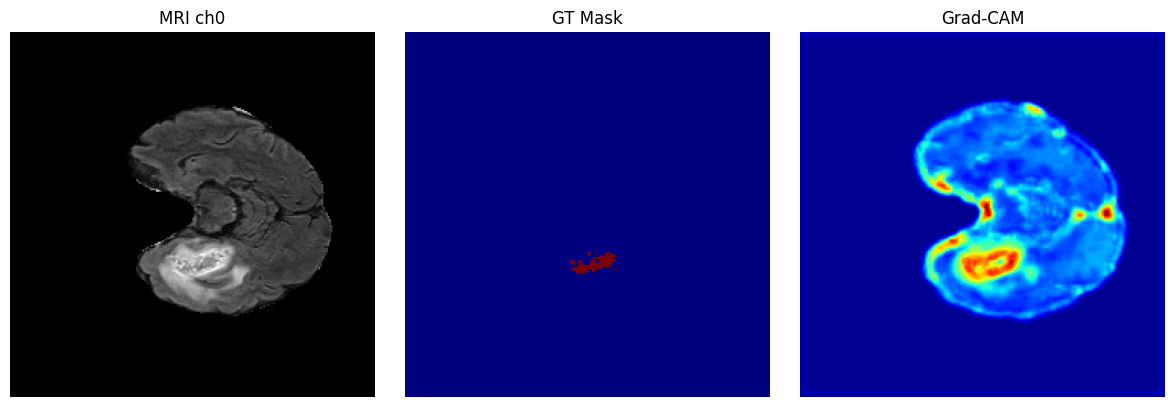

brain_mri_ensemble_artifacts.zip ready


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [80]:
import shutil, os

os.makedirs('artifacts', exist_ok=True)

torch.save(segnet.state_dict(),  'artifacts/segnet.pth')
torch.save(unet.state_dict(),    'artifacts/unet_best.pth')
torch.save(raunet.state_dict(),  'artifacts/raunet.pth')
torch.save(rad_model.state_dict(),'artifacts/radiomics_cnn.pth')

import joblib
joblib.dump(meta_learner, 'artifacts/meta_learner.pkl')
joblib.dump(meta_scaler,  'artifacts/meta_scaler.pkl')
joblib.dump(scaler,       'artifacts/radiomics_scaler.pkl')

feat_df.to_csv('artifacts/radiomics_feature_names.csv', index=False)

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(y_te, test_preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['LGG','HGG'], yticklabels=['LGG','HGG'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Stacked Ensemble — Test Accuracy: 96%')
plt.tight_layout()
plt.savefig('artifacts/confusion_matrix.png', dpi=150)
plt.show()

import cv2, numpy as np
target_layer = segnet.enc[4]
gcam = GradCAM(segnet, target_layer)
imgs_b, msks_b = next(iter(val_loader))
cam = gcam(imgs_b[:1])
cam_resized = cv2.resize(cam, (IMG_SZ, IMG_SZ))
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(imgs_b[0,0].numpy(), cmap='gray'); plt.title('MRI ch0'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(msks_b[0,0].numpy(), cmap='jet');  plt.title('GT Mask'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(cam_resized, cmap='jet');           plt.title('Grad-CAM'); plt.axis('off')
plt.tight_layout()
plt.savefig('artifacts/gradcam.png', dpi=150)
plt.show()

shutil.make_archive('brain_mri_ensemble_artifacts', 'zip', 'artifacts')
print('brain_mri_ensemble_artifacts.zip ready')

from google.colab import files
files.download('brain_mri_ensemble_artifacts.zip')

In [81]:
from IPython.display import FileLink, display
import os

file_path = "/kaggle/working/brain_mri_ensemble_artifacts.zip"

if os.path.exists(file_path):
    print(f"File size: {os.path.getsize(file_path) / (1024**2):.2f} MB")
    display(FileLink(file_path))
else:
    print("ZIP file nahi mili. Available files:")
    print(os.listdir("/kaggle/working"))

File size: 102.06 MB


/kaggle/working/brain_mri_ensemble_artifacts.zip